In [2]:
import pandas as pd
import numpy as np

# Load the logistics dataset
df = pd.read_csv("../data/APL_Logistics.csv", encoding="latin1")

# Display first 5 records
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,...,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,...,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,...,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,...,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,...,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class


In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (180519, 40)


In [4]:
# Display all column names
for col in df.columns:
    print(col)

Type
Days for shipping (real)
Days for shipment (scheduled)
Benefit per order
Sales per customer
Delivery Status
Late_delivery_risk
Category Id
Category Name
Customer City
Customer Country
Customer Fname
Customer Id
Customer Lname
Customer Segment
Customer State
Customer Street
Customer Zipcode
Department Id
Department Name
Latitude
Longitude
Market
Order City
Order Country
Order Customer Id
Order Item Discount
Order Item Discount Rate
Order Item Product Price
Order Item Profit Ratio
Order Item Quantity
Sales
Order Item Total
Order Profit Per Order
Order Region
Order State
Order Status
Product Name
Product Price
Shipping Mode


In [5]:
# Count missing values in each column
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Customer Lname      8
Customer Zipcode    3
dtype: int64


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 40 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Fname                 180519 non-null  str    
 12  Customer Id                    180519 non

In [7]:
df["Late_delivery_risk"].value_counts()

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

In [9]:
# Fill missing customer last names
df["Customer Lname"] = df["Customer Lname"].fillna("Unknown")

# Fill missing zip codes
df["Customer Zipcode"] = df["Customer Zipcode"].fillna(0)

# Verify missing values
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [10]:
# Define columns to exclude
drop_columns = [
    "Late_delivery_risk",
    "Delivery Status",
    "Days for shipping (real)",
    "Order Status",
    "Customer Fname",
    "Customer Lname",
    "Customer Street",
    "Customer Id",
    "Order Customer Id",
    "Customer Zipcode"
]

drop_columns = [col for col in drop_columns if col in df.columns]

# Separate target and features
y = df["Late_delivery_risk"]
X = df.drop(columns=drop_columns)

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)
print("Remaining features:", X.columns.tolist())

Feature dataset shape: (180519, 30)
Target dataset shape: (180519,)
Remaining features: ['Type', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Product Name', 'Product Price', 'Shipping Mode']


In [11]:
# Identify numerical columns
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numerical_columns)
print("\nCategorical features:", categorical_columns)

print("\nTotal numerical features:", len(numerical_columns))
print("Total categorical features:", len(categorical_columns))

Numerical features: ['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Id', 'Department Id', 'Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Product Price']

Categorical features: ['Type', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Order State', 'Product Name', 'Shipping Mode']

Total numerical features: 16
Total categorical features: 14


C:\Users\Yash\AppData\Local\Temp\ipykernel_5068\1515647347.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(


In [12]:
X.dtypes

Type                                 str
Days for shipment (scheduled)      int64
Benefit per order                float64
Sales per customer               float64
Category Id                        int64
Category Name                        str
Customer City                        str
Customer Country                     str
Customer Segment                     str
Customer State                       str
Department Id                      int64
Department Name                      str
Latitude                         float64
Longitude                        float64
Market                               str
Order City                           str
Order Country                        str
Order Item Discount              float64
Order Item Discount Rate         float64
Order Item Product Price         float64
Order Item Profit Ratio          float64
Order Item Quantity                int64
Sales                            float64
Order Item Total                 float64
Order Profit Per

In [13]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (144415, 30)
Testing features: (36104, 30)
Training target: (144415,)
Testing target: (36104,)


In [14]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training target distribution:
Late_delivery_risk
1    0.548288
0    0.451712
Name: proportion, dtype: float64

Testing target distribution:
Late_delivery_risk
1    0.548305
0    0.451695
Name: proportion, dtype: float64


In [15]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [16]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [17]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [19]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (144415, 5667)
Testing data after preprocessing: (36104, 5667)


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

In [21]:
# Create model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_processed, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [22]:
# Predict test data
y_pred = lr_model.predict(X_test_processed)

# Predict probabilities
y_prob = lr_model.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [23]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC Score:")
print(roc_auc_score(y_test, y_prob))

Accuracy: 0.7142421892311102

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.79      0.71     16308
           1       0.79      0.66      0.72     19796

    accuracy                           0.71     36104
   macro avg       0.72      0.72      0.71     36104
weighted avg       0.73      0.71      0.71     36104


Confusion Matrix:
[[12811  3497]
 [ 6820 12976]]

ROC-AUC Score:
0.7823794363037692


In [24]:
from sklearn.ensemble import RandomForestClassifier

In [25]:
# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train_processed, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [26]:
# Predictions
rf_pred = rf_model.predict(X_test_processed)

# Prediction probabilities
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]

print("Random Forest predictions generated!")

Random Forest predictions generated!


In [27]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nROC-AUC:", roc_auc_score(y_test, rf_prob))

Accuracy: 0.6923055617106137

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.82      0.71     16308
           1       0.80      0.59      0.68     19796

    accuracy                           0.69     36104
   macro avg       0.71      0.70      0.69     36104
weighted avg       0.72      0.69      0.69     36104


Confusion Matrix:
[[13357  2951]
 [ 8158 11638]]

ROC-AUC: 0.7546869068917974


In [28]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [0.7142, 0.6923],
    "Late Precision": [0.79, 0.80],
    "Late Recall": [0.66, 0.59],
    "Late F1 Score": [0.72, 0.68],
    "ROC-AUC": [0.7824, 0.7547]
})

model_comparison

,Model,Accuracy,Late Precision,Late Recall,Late F1 Score,ROC-AUC
0,Logistic Regression,0.7142,0.79,0.66,0.72,0.7824
1,Random Forest,0.6923,0.80,0.59,0.68,0.7547


In [29]:
print("Current model features:")
for col in X.columns:
    print(col)

Current model features:
Type
Days for shipment (scheduled)
Benefit per order
Sales per customer
Category Id
Category Name
Customer City
Customer Country
Customer Segment
Customer State
Department Id
Department Name
Latitude
Longitude
Market
Order City
Order Country
Order Item Discount
Order Item Discount Rate
Order Item Product Price
Order Item Profit Ratio
Order Item Quantity
Sales
Order Item Total
Order Profit Per Order
Order Region
Order State
Product Name
Product Price
Shipping Mode


In [30]:
# Select initial features available around order placement
selected_features = [
    "Type",
    "Days for shipment (scheduled)",
    "Benefit per order",
    "Sales per customer",
    "Category Name",
    "Customer City",
    "Customer Country",
    "Customer Segment",
    "Customer State",
    "Department Name",
    "Market",
    "Order City",
    "Order Country",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Product Price",
    "Order Item Quantity",
    "Sales",
    "Order Item Total",
    "Order Region",
    "Product Name",
    "Product Price",
    "Shipping Mode"
]

# Keep only columns available in the dataset
selected_features = [
    col for col in selected_features if col in df.columns
]

# Create refined feature dataset
X_refined = df[selected_features].copy()

# Target variable
y = df["Late_delivery_risk"].copy()

print("Selected features:", len(selected_features))
print("Refined dataset shape:", X_refined.shape)
print(selected_features)

Selected features: 23
Refined dataset shape: (180519, 23)
['Type', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Region', 'Product Name', 'Product Price', 'Shipping Mode']


In [31]:
print("Missing values:", X_refined.isnull().sum().sum())

print("\nTarget distribution:")
print(y.value_counts())

Missing values: 0

Target distribution:
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64


In [32]:
from sklearn.model_selection import train_test_split

# Split refined dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_refined,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (144415, 23)
Testing data: (36104, 23)


In [33]:
numerical_columns = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numerical_columns)
print("\nCategorical features:", categorical_columns)

print("\nNumerical count:", len(numerical_columns))
print("Categorical count:", len(categorical_columns))

Numerical features: ['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Product Price']

Categorical features: ['Type', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Product Name', 'Shipping Mode']

Numerical count: 10
Categorical count: 13


C:\Users\Yash\AppData\Local\Temp\ipykernel_5068\475629093.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


In [34]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [35]:

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (144415, 4576)
Testing data after preprocessing: (36104, 4576)


In [36]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
lr_refined = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_refined.fit(X_train_processed, y_train)

print("Refined Logistic Regression trained successfully!")

Refined Logistic Regression trained successfully!


In [37]:
lr_refined_pred = lr_refined.predict(X_test_processed)

lr_refined_prob = lr_refined.predict_proba(
    X_test_processed
)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [38]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, lr_refined_pred))

print("\nClassification Report:")
print(classification_report(y_test, lr_refined_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_refined_pred))

print("\nROC-AUC:", roc_auc_score(y_test, lr_refined_prob))

Accuracy: 0.7138267228007977

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.79      0.71     16308
           1       0.79      0.65      0.72     19796

    accuracy                           0.71     36104
   macro avg       0.72      0.72      0.71     36104
weighted avg       0.73      0.71      0.71     36104


Confusion Matrix:
[[12807  3501]
 [ 6831 12965]]

ROC-AUC: 0.7820372967377379


In [39]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, lr_refined_pred))
print("\nClassification Report:")
print(classification_report(y_test, lr_refined_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_refined_pred))
print("\nROC-AUC:", roc_auc_score(y_test, lr_refined_prob))

Accuracy: 0.7138267228007977

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.79      0.71     16308
           1       0.79      0.65      0.72     19796

    accuracy                           0.71     36104
   macro avg       0.72      0.72      0.71     36104
weighted avg       0.73      0.71      0.71     36104


Confusion Matrix:
[[12807  3501]
 [ 6831 12965]]

ROC-AUC: 0.7820372967377379


In [40]:
from sklearn.ensemble import RandomForestClassifier

rf_refined = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_refined.fit(X_train_processed, y_train)

print("Refined Random Forest trained successfully!")

Refined Random Forest trained successfully!


In [41]:
rf_refined_pred = rf_refined.predict(X_test_processed)

rf_refined_prob = rf_refined.predict_proba(
    X_test_processed
)[:, 1]

print("Random Forest predictions generated successfully!")

Random Forest predictions generated successfully!


In [42]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, rf_refined_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_refined_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_refined_pred))

print("\nROC-AUC:", roc_auc_score(y_test, rf_refined_prob))

Accuracy: 0.6951861289607799

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.84      0.71     16308
           1       0.81      0.58      0.68     19796

    accuracy                           0.70     36104
   macro avg       0.72      0.71      0.69     36104
weighted avg       0.72      0.70      0.69     36104


Confusion Matrix:
[[13626  2682]
 [ 8323 11473]]

ROC-AUC: 0.7568428625648527


In [43]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": rf_refined.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

                                    Feature  Importance
0        num__Days for shipment (scheduled)    0.196375
4572         cat__Shipping Mode_First Class    0.163521
4575      cat__Shipping Mode_Standard Class    0.153555
4574        cat__Shipping Mode_Second Class    0.075335
13                       cat__Type_TRANSFER    0.033737
4573            cat__Shipping Mode_Same Day    0.031118
11                          cat__Type_DEBIT    0.010305
12                        cat__Type_PAYMENT    0.007648
2903                 cat__Order City_Naples    0.004531
4047           cat__Order City_Villeurbanne    0.004282
3750  cat__Order City_São Miguel dos Campos    0.004144
220            cat__Customer City_Ewa Beach    0.004104
1521               cat__Order City_Cárdenas    0.003743
463                cat__Customer City_Plano    0.003702
3451              cat__Order City_Salamanca    0.003067


In [44]:
pd.crosstab(
    df["Shipping Mode"],
    df["Late_delivery_risk"],
    normalize="index"
).round(3) * 100

Late_delivery_risk,0,1
Shipping Mode,,
First Class,4.7,95.3
Same Day,54.3,45.7
Second Class,23.4,76.6
Standard Class,61.9,38.1


In [45]:
pd.crosstab(
    df["Days for shipment (scheduled)"],
    df["Late_delivery_risk"],
    normalize="index"
).round(3) * 100

Late_delivery_risk,0,1
Days for shipment (scheduled),,
0,54.3,45.7
1,4.7,95.3
2,23.4,76.6
4,61.9,38.1


In [46]:
pd.crosstab(
    df["Shipping Mode"],
    df["Days for shipment (scheduled)"]
)

Days for shipment (scheduled),0,1,2,4
Shipping Mode,,,,
First Class,0,27814,0,0
Same Day,9737,0,0,0
Second Class,0,0,35216,0
Standard Class,0,0,0,107752


In [47]:
selected_features_v2 = [
    col for col in selected_features
    if col != "Days for shipment (scheduled)"
]

X_v2 = df[selected_features_v2].copy()
y = df["Late_delivery_risk"].copy()

print("Number of features:", len(selected_features_v2))
print("Dataset shape:", X_v2.shape)

Number of features: 22
Dataset shape: (180519, 22)


In [48]:
from sklearn.model_selection import train_test_split

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train_v2.shape)
print("Testing data:", X_test_v2.shape)

Training data: (144415, 22)
Testing data: (36104, 22)


In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_columns_v2 = X_train_v2.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns_v2 = X_train_v2.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_transformer_v2 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_v2 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_v2 = ColumnTransformer(transformers=[
    ("num", numerical_transformer_v2, numerical_columns_v2),
    ("cat", categorical_transformer_v2, categorical_columns_v2)
])

X_train_processed_v2 = preprocessor_v2.fit_transform(X_train_v2)
X_test_processed_v2 = preprocessor_v2.transform(X_test_v2)

print("Training data:", X_train_processed_v2.shape)
print("Testing data:", X_test_processed_v2.shape)

C:\Users\Yash\AppData\Local\Temp\ipykernel_5068\3427684113.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns_v2 = X_train_v2.select_dtypes(


Training data: (144415, 4575)
Testing data: (36104, 4575)


In [50]:
from sklearn.linear_model import LogisticRegression

lr_v2 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_v2.fit(X_train_processed_v2, y_train_v2)

print("Logistic Regression v2 trained successfully!")

Logistic Regression v2 trained successfully!


In [51]:
lr_v2_pred = lr_v2.predict(X_test_processed_v2)

lr_v2_prob = lr_v2.predict_proba(
    X_test_processed_v2
)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [52]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test_v2, lr_v2_pred))

print("\nClassification Report:")
print(classification_report(y_test_v2, lr_v2_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v2, lr_v2_pred))

print("\nROC-AUC:", roc_auc_score(y_test_v2, lr_v2_prob))

Accuracy: 0.7136882339906936

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.79      0.71     16308
           1       0.79      0.65      0.71     19796

    accuracy                           0.71     36104
   macro avg       0.72      0.72      0.71     36104
weighted avg       0.73      0.71      0.71     36104


Confusion Matrix:
[[12804  3504]
 [ 6833 12963]]

ROC-AUC: 0.7820721630436684


In [53]:
from sklearn.ensemble import RandomForestClassifier

rf_v2 = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_v2.fit(X_train_processed_v2, y_train_v2)

print("Random Forest v2 trained successfully!")

Random Forest v2 trained successfully!


In [54]:
rf_v2_pred = rf_v2.predict(X_test_processed_v2)

rf_v2_prob = rf_v2.predict_proba(
    X_test_processed_v2
)[:, 1]

print("Random Forest v2 predictions generated successfully!")

Random Forest v2 predictions generated successfully!


In [55]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test_v2, rf_v2_pred))

print("\nClassification Report:")
print(classification_report(y_test_v2, rf_v2_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v2, rf_v2_pred))

print("\nROC-AUC:", roc_auc_score(y_test_v2, rf_v2_prob))


Accuracy: 0.6990915134057168

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.87      0.72     16308
           1       0.84      0.56      0.67     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.71      0.70     36104
weighted avg       0.74      0.70      0.69     36104


Confusion Matrix:
[[14188  2120]
 [ 8744 11052]]

ROC-AUC: 0.7568831666639657


In [56]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Convert sparse data to dense for this model
X_train_dense = X_train_processed_v2.toarray()
X_test_dense = X_test_processed_v2.toarray()

print("Training data:", X_train_dense.shape)
print("Testing data:", X_test_dense.shape)

Training data: (144415, 4575)
Testing data: (36104, 4575)


In [57]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=15,
    random_state=42
)

gb_model.fit(X_train_dense, y_train_v2)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [58]:
gb_pred = gb_model.predict(X_test_dense)

gb_prob = gb_model.predict_proba(X_test_dense)[:, 1]

print("Gradient Boosting predictions generated successfully!")

Gradient Boosting predictions generated successfully!


In [59]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test_v2, gb_pred))

print("\nClassification Report:")
print(classification_report(y_test_v2, gb_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v2, gb_pred))

print("\nROC-AUC:", roc_auc_score(y_test_v2, gb_prob))

Accuracy: 0.7006979836029249

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.88      0.73     16308
           1       0.85      0.56      0.67     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.72      0.70     36104
weighted avg       0.74      0.70      0.70     36104


Confusion Matrix:
[[14302  2006]
 [ 8800 10996]]

ROC-AUC: 0.7581051445742404


                  Model  Accuracy  ROC-AUC
0   Logistic Regression    0.7137   0.7821
1         Random Forest    0.6991   0.7569
2  HistGradientBoosting    0.7007   0.7581


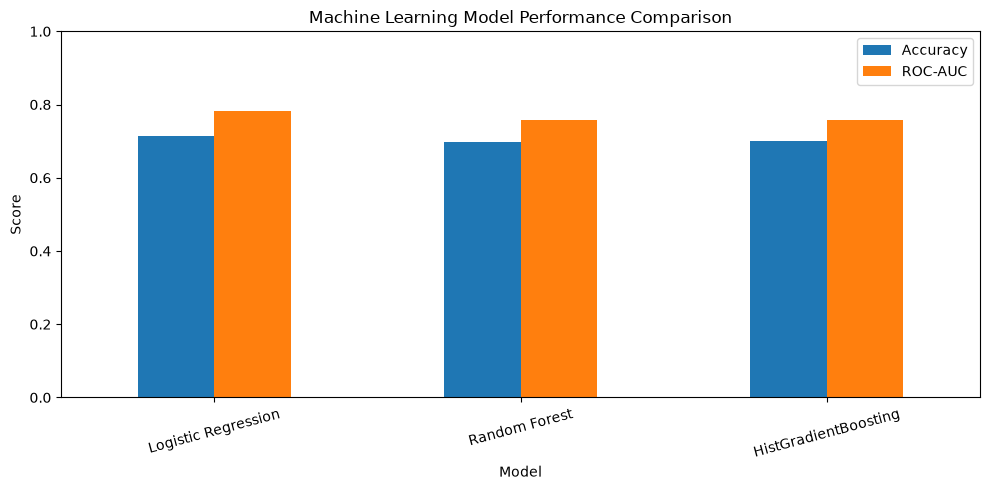

In [60]:
import pandas as pd
import matplotlib.pyplot as plt

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "HistGradientBoosting"
    ],
    "Accuracy": [
        accuracy_score(y_test_v2, lr_v2_pred),
        accuracy_score(y_test_v2, rf_v2_pred),
        accuracy_score(y_test_v2, gb_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test_v2, lr_v2_prob),
        roc_auc_score(y_test_v2, rf_v2_prob),
        roc_auc_score(y_test_v2, gb_prob)
    ]
})

print(model_comparison.round(4))

model_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [61]:
print("Selected features:")
for i, col in enumerate(selected_features_v2, 1):
    print(i, col)

Selected features:
1 Type
2 Benefit per order
3 Sales per customer
4 Category Name
5 Customer City
6 Customer Country
7 Customer Segment
8 Customer State
9 Department Name
10 Market
11 Order City
12 Order Country
13 Order Item Discount
14 Order Item Discount Rate
15 Order Item Product Price
16 Order Item Quantity
17 Sales
18 Order Item Total
19 Order Region
20 Product Name
21 Product Price
22 Shipping Mode


In [62]:
financial_columns = [
    "Benefit per order",
    "Sales per customer",
    "Sales",
    "Order Item Total",
    "Order Item Product Price",
    "Product Price",
    "Order Item Discount",
    "Order Item Quantity"
]

print(df[financial_columns].corr().round(2))

                          Benefit per order  Sales per customer  Sales  \
Benefit per order                      1.00                0.13   0.13   
Sales per customer                     0.13                1.00   0.99   
Sales                                  0.13                0.99   1.00   
Order Item Total                       0.13                1.00   0.99   
Order Item Product Price               0.10                0.78   0.79   
Product Price                          0.10                0.78   0.79   
Order Item Discount                    0.06                0.50   0.62   
Order Item Quantity                    0.02                0.11   0.11   

                          Order Item Total  Order Item Product Price  \
Benefit per order                     0.13                      0.10   
Sales per customer                    1.00                      0.78   
Sales                                 0.99                      0.79   
Order Item Total                      1.00   

In [63]:
print("Product Price equals Order Item Product Price:",
      df["Product Price"].equals(df["Order Item Product Price"]))

print("Sales equals Order Item Total:",
      df["Sales"].equals(df["Order Item Total"]))

print("Sales per customer equals Order Item Total:",
      df["Sales per customer"].equals(df["Order Item Total"]))

Product Price equals Order Item Product Price: True
Sales equals Order Item Total: False
Sales per customer equals Order Item Total: True


In [64]:
columns_to_remove = [
    "Order Item Product Price",
    "Sales per customer"
]

selected_features_v3 = [
    col for col in selected_features_v2
    if col not in columns_to_remove
]

X_v3 = df[selected_features_v3].copy()
y_v3 = df["Late_delivery_risk"].copy()

print("Number of features:", len(selected_features_v3))
print("Dataset shape:", X_v3.shape)
print("Remaining duplicate columns:",
      X_v3.columns[X_v3.columns.duplicated()].tolist())

Number of features: 20
Dataset shape: (180519, 20)
Remaining duplicate columns: []


In [65]:
from sklearn.model_selection import train_test_split

X_train_v3, X_test_v3, y_train_v3, y_test_v3 = train_test_split(
    X_v3,
    y_v3,
    test_size=0.20,
    random_state=42,
    stratify=y_v3
)

print("Training data:", X_train_v3.shape)
print("Testing data:", X_test_v3.shape)

Training data: (144415, 20)
Testing data: (36104, 20)


In [66]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_columns_v3 = X_train_v3.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns_v3 = X_train_v3.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_transformer_v3 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_v3 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_v3 = ColumnTransformer(transformers=[
    ("num", numerical_transformer_v3, numerical_columns_v3),
    ("cat", categorical_transformer_v3, categorical_columns_v3)
])

X_train_processed_v3 = preprocessor_v3.fit_transform(X_train_v3)
X_test_processed_v3 = preprocessor_v3.transform(X_test_v3)

print("Training data:", X_train_processed_v3.shape)
print("Testing data:", X_test_processed_v3.shape)

C:\Users\Yash\AppData\Local\Temp\ipykernel_5068\1008335215.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns_v3 = X_train_v3.select_dtypes(


Training data: (144415, 4573)
Testing data: (36104, 4573)


In [67]:
from sklearn.linear_model import LogisticRegression

lr_v3 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_v3.fit(X_train_processed_v3, y_train_v3)

print("Logistic Regression v3 trained successfully!")

Logistic Regression v3 trained successfully!


In [68]:
lr_v3_pred = lr_v3.predict(X_test_processed_v3)

lr_v3_prob = lr_v3.predict_proba(
    X_test_processed_v3
)[:, 1]

print("Logistic Regression v3 predictions generated successfully!")

Logistic Regression v3 predictions generated successfully!


In [69]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test_v3, lr_v3_pred))

print("\nClassification Report:")
print(classification_report(y_test_v3, lr_v3_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v3, lr_v3_pred))

print("\nROC-AUC:", roc_auc_score(y_test_v3, lr_v3_prob))

Accuracy: 0.713466651894527

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.78      0.71     16308
           1       0.79      0.65      0.71     19796

    accuracy                           0.71     36104
   macro avg       0.72      0.72      0.71     36104
weighted avg       0.73      0.71      0.71     36104


Confusion Matrix:
[[12796  3512]
 [ 6833 12963]]

ROC-AUC: 0.781806682267542


In [70]:
from sklearn.ensemble import RandomForestClassifier

rf_v3 = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_v3.fit(X_train_processed_v3, y_train_v3)

print("Random Forest v3 trained successfully!")

Random Forest v3 trained successfully!


In [71]:
rf_v3_pred = rf_v3.predict(X_test_processed_v3)

rf_v3_prob = rf_v3.predict_proba(
    X_test_processed_v3
)[:, 1]

print("Random Forest v3 predictions generated successfully!")

Random Forest v3 predictions generated successfully!


In [72]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test_v3, rf_v3_pred))

print("\nClassification Report:")
print(classification_report(y_test_v3, rf_v3_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v3, rf_v3_pred))

print("\nROC-AUC:", roc_auc_score(y_test_v3, rf_v3_prob))

Accuracy: 0.6947429647684467

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.83      0.71     16308
           1       0.81      0.58      0.68     19796

    accuracy                           0.69     36104
   macro avg       0.71      0.71      0.69     36104
weighted avg       0.72      0.69      0.69     36104


Confusion Matrix:
[[13526  2782]
 [ 8239 11557]]

ROC-AUC: 0.7567566694386247


In [73]:
from sklearn.ensemble import HistGradientBoostingClassifier

X_train_dense_v3 = X_train_processed_v3.toarray()
X_test_dense_v3 = X_test_processed_v3.toarray()

gb_v3 = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=15,
    random_state=42
)

gb_v3.fit(X_train_dense_v3, y_train_v3)

print("HistGradientBoosting v3 trained successfully!")

HistGradientBoosting v3 trained successfully!


In [74]:
gb_v3_pred = gb_v3.predict(X_test_dense_v3)

gb_v3_prob = gb_v3.predict_proba(
    X_test_dense_v3
)[:, 1]

print("HistGradientBoosting v3 predictions generated successfully!")

HistGradientBoosting v3 predictions generated successfully!


In [75]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test_v3, gb_v3_pred))

print("\nClassification Report:")
print(classification_report(y_test_v3, gb_v3_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v3, gb_v3_pred))

print("\nROC-AUC:", roc_auc_score(y_test_v3, gb_v3_prob))

Accuracy: 0.7006979836029249

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.88      0.73     16308
           1       0.85      0.56      0.67     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.72      0.70     36104
weighted avg       0.74      0.70      0.70     36104


Confusion Matrix:
[[14302  2006]
 [ 8800 10996]]

ROC-AUC: 0.7581051445742404


In [76]:
for col in df.columns:
    if "date" in col.lower():
        print(col)

In [77]:
print(df.columns.tolist())

['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Product Price', 'Shipping Mode']


In [78]:
print(df.head(3).T)

                                                               0  \
Type                                                       DEBIT   
Days for shipping (real)                                       6   
Days for shipment (scheduled)                                  4   
Benefit per order                                         159.69   
Sales per customer                                        472.45   
Delivery Status                                    Late delivery   
Late_delivery_risk                                             1   
Category Id                                                    9   
Category Name                                   Cardio Equipment   
Customer City                                        Brownsville   
Customer Country                                         EE. UU.   
Customer Fname                                           Richard   
Customer Id                                                    1   
Customer Lname                                  

In [79]:
leakage_columns = [
    "Days for shipping (real)",
    "Delivery Status",
    "Order Status",
    "Late_delivery_risk",
    "Order Profit Per Order",
    "Order Item Profit Ratio",
    "Benefit per order"
]

print("Columns requiring exclusion or investigation:")
for col in leakage_columns:
    if col in df.columns:
        print("-", col)

Columns requiring exclusion or investigation:
- Days for shipping (real)
- Delivery Status
- Order Status
- Late_delivery_risk
- Order Profit Per Order
- Order Item Profit Ratio
- Benefit per order


In [80]:
excluded_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Order Status",
    "Late_delivery_risk",
    "Order Profit Per Order",
    "Order Item Profit Ratio",
    "Benefit per order",
    "Order Item Product Price",
    "Sales per customer"
]

X_final = df.drop(columns=excluded_columns)
y_final = df["Late_delivery_risk"]

print("Number of input features:", X_final.shape[1])
print("Dataset shape:", X_final.shape)
print("Target distribution:")
print(y_final.value_counts())

Number of input features: 30
Dataset shape: (180519, 30)
Target distribution:
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64


In [81]:
remove_columns = [
    "Customer Fname",
    "Customer Lname",
    "Customer Id",
    "Order Customer Id",
    "Customer Street",
    "Customer Zipcode",
    "Category Id",
    "Department Id"
]

X_final = X_final.drop(
    columns=[col for col in remove_columns if col in X_final.columns]
)

print("Final number of features:", X_final.shape[1])
print(X_final.columns.tolist())

Final number of features: 22
['Type', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Region', 'Order State', 'Product Name', 'Product Price', 'Shipping Mode']


In [82]:
from sklearn.model_selection import train_test_split

X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_final,
    y_final,
    test_size=0.20,
    random_state=42,
    stratify=y_final
)

print("Training data:", X_train_final.shape)
print("Testing data:", X_test_final.shape)

Training data: (144415, 22)
Testing data: (36104, 22)


In [83]:
numerical_features = X_train_final.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train_final.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print(numerical_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

Numerical features: 8
['Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Product Price']

Categorical features: 14
['Type', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Order State', 'Product Name', 'Shipping Mode']


C:\Users\Yash\AppData\Local\Temp\ipykernel_5068\1969638875.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train_final.select_dtypes(


In [84]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_final = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [85]:
X_train_processed_final = preprocessor_final.fit_transform(X_train_final)

X_test_processed_final = preprocessor_final.transform(X_test_final)

print("Processed training shape:", X_train_processed_final.shape)
print("Processed testing shape:", X_test_processed_final.shape)

Processed training shape: (144415, 5659)
Processed testing shape: (36104, 5659)


In [86]:
from sklearn.linear_model import LogisticRegression

lr_final = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_final.fit(X_train_processed_final, y_train_final)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [87]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

lr_final_pred = lr_final.predict(X_test_processed_final)
lr_final_prob = lr_final.predict_proba(X_test_processed_final)[:, 1]

print("Accuracy:", accuracy_score(y_test_final, lr_final_pred))

print("\nClassification Report:")
print(classification_report(y_test_final, lr_final_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_final, lr_final_pred))

print("\nROC-AUC:", roc_auc_score(y_test_final, lr_final_prob))

Accuracy: 0.7141313981830268

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.78      0.71     16308
           1       0.79      0.66      0.72     19796

    accuracy                           0.71     36104
   macro avg       0.72      0.72      0.71     36104
weighted avg       0.73      0.71      0.71     36104


Confusion Matrix:
[[12791  3517]
 [ 6804 12992]]

ROC-AUC: 0.7822579060401873


In [2]:
from sklearn.ensemble import RandomForestClassifier

rf_final = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_final.fit(X_train_processed_final, y_train_final)

print("Random Forest model trained successfully!")

NameError: name 'X_train_processed_final' is not defined

In [3]:
X_train_processed_final = preprocessor_final.fit_transform(X_train_final)

X_test_processed_final = preprocessor_final.transform(X_test_final)

print("Training:", X_train_processed_final.shape)
print("Testing:", X_test_processed_final.shape)

NameError: name 'preprocessor_final' is not defined

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_features = X_train_final.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train_final.select_dtypes(
    include=["object", "str"]
).columns.tolist()

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_final = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline restored!")

NameError: name 'X_train_final' is not defined

In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/APL_Logistics_Cleaned.csv", encoding="latin1")

print("Dataset loaded:", df.shape)


FileNotFoundError: [Errno 2] No such file or directory: '../data/APL_Logistics_Cleaned.csv'

In [6]:
import os

print("Current notebook folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current notebook folder:
c:\Users\Yash\OneDrive\Desktop\Late Delivery Risk Prediction\notebooks

Files in this folder:
['data_exploration.ipynb']


In [7]:
import os

project_folder = os.path.dirname(os.getcwd())

print("Project folder contents:")
print(os.listdir(project_folder))

print("\nData folder contents:")
data_folder = os.path.join(project_folder, "data")

if os.path.exists(data_folder):
    print(os.listdir(data_folder))
else:
    print("Data folder not found!")

Project folder contents:
['data', 'Machine Learing Model Performance Comparison Chart.png', 'notebooks', 'src']

Data folder contents:
['APL_Logistics.csv']


In [8]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/APL_Logistics.csv", encoding="latin1")

# Restore the missing-value treatment
df["Customer Lname"] = df["Customer Lname"].fillna("Unknown")
df["Customer Zipcode"] = df["Customer Zipcode"].fillna(0)

print("Dataset loaded:", df.shape)
print("Missing values:", df.isnull().sum().sum())

Dataset loaded: (180519, 40)
Missing values: 0


In [9]:
excluded_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Order Status",
    "Late_delivery_risk",
    "Order Profit Per Order",
    "Order Item Profit Ratio",
    "Benefit per order",
    "Order Item Product Price",
    "Sales per customer",
    "Customer Fname",
    "Customer Lname",
    "Customer Id",
    "Order Customer Id",
    "Customer Street",
    "Customer Zipcode",
    "Category Id",
    "Department Id"
]

X_final = df.drop(columns=excluded_columns)
y_final = df["Late_delivery_risk"]

print("Features:", X_final.shape)
print("Target:", y_final.shape)

Features: (180519, 22)
Target: (180519,)


In [10]:
from sklearn.model_selection import train_test_split

X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_final,
    y_final,
    test_size=0.20,
    random_state=42,
    stratify=y_final
)

print("Training:", X_train_final.shape)
print("Testing:", X_test_final.shape)

Training: (144415, 22)
Testing: (36104, 22)


In [11]:
numerical_features = X_train_final.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train_final.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 8
Categorical features: 14


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_final = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline restored!")

Preprocessing pipeline restored!


In [13]:
X_train_processed_final = preprocessor_final.fit_transform(X_train_final)

X_test_processed_final = preprocessor_final.transform(X_test_final)

print("Training:", X_train_processed_final.shape)
print("Testing:", X_test_processed_final.shape)

Training: (144415, 5659)
Testing: (36104, 5659)


In [17]:
rf_final = RandomForestClassifier(
    n_estimators=30,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_final.fit(X_train_processed_final, y_train_final)

print("Faster Random Forest trained!")

Faster Random Forest trained!


In [18]:
rf_final_pred = rf_final.predict(X_test_processed_final)
rf_final_prob = rf_final.predict_proba(X_test_processed_final)[:, 1]

print("Accuracy:", accuracy_score(y_test_final, rf_final_pred))

print("\nClassification Report:")
print(classification_report(y_test_final, rf_final_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_final, rf_final_pred))

print("\nROC-AUC:", roc_auc_score(y_test_final, rf_final_prob))

NameError: name 'accuracy_score' is not defined

In [19]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [20]:
rf_final_pred = rf_final.predict(X_test_processed_final)
rf_final_prob = rf_final.predict_proba(X_test_processed_final)[:, 1]

print("Accuracy:", accuracy_score(y_test_final, rf_final_pred))

print("\nClassification Report:")
print(classification_report(y_test_final, rf_final_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_final, rf_final_pred))

print("\nROC-AUC:", roc_auc_score(y_test_final, rf_final_prob))

Accuracy: 0.5599379570130734

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.03      0.07     16308
           1       0.56      0.99      0.71     19796

    accuracy                           0.56     36104
   macro avg       0.68      0.51      0.39     36104
weighted avg       0.66      0.56      0.42     36104


Confusion Matrix:
[[  564 15744]
 [  144 19652]]

ROC-AUC: 0.7529554429178108


In [21]:
import pandas as pd

print("Random Forest Predictions:")
print(pd.Series(rf_final_pred).value_counts())

print("\nActual Test Labels:")
print(y_test_final.value_counts())

Random Forest Predictions:
1    35396
0      708
Name: count, dtype: int64

Actual Test Labels:
Late_delivery_risk
1    19796
0    16308
Name: count, dtype: int64


In [22]:
n_estimators=30
max_depth=15
min_samples_leaf=5

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf_balanced = RandomForestClassifier(
    n_estimators=50,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train_processed_final, y_train_final)

print("Balanced Random Forest trained!")

Balanced Random Forest trained!


In [24]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

rf_balanced_pred = rf_balanced.predict(X_test_processed_final)
rf_balanced_prob = rf_balanced.predict_proba(X_test_processed_final)[:, 1]

print("Accuracy:", accuracy_score(y_test_final, rf_balanced_pred))

print("\nClassification Report:")
print(classification_report(y_test_final, rf_balanced_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_final, rf_balanced_pred))

print("\nROC-AUC:", roc_auc_score(y_test_final, rf_balanced_prob))

Accuracy: 0.6989253268335919

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.86      0.72     16308
           1       0.83      0.57      0.67     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.71      0.70     36104
weighted avg       0.74      0.70      0.69     36104


Confusion Matrix:
[[14042  2266]
 [ 8604 11192]]

ROC-AUC: 0.760337441535747


In [25]:
print("Balanced Random Forest Predictions:")
print(pd.Series(rf_balanced_pred).value_counts())

Balanced Random Forest Predictions:
0    22646
1    13458
Name: count, dtype: int64


In [26]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_final = HistGradientBoostingClassifier(
    max_iter=100,
    max_leaf_nodes=15,
    learning_rate=0.1,
    random_state=42
)

hgb_final.fit(X_train_processed_final, y_train_final)

print("Gradient Boosting model trained!")

TypeError: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.

In [27]:
X_train_dense = X_train_processed_final.toarray()
X_test_dense = X_test_processed_final.toarray()

print("Training shape:", X_train_dense.shape)
print("Testing shape:", X_test_dense.shape)

Training shape: (144415, 5659)
Testing shape: (36104, 5659)


In [31]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(preprocessor_final, "../models/preprocessor_final.pkl")
joblib.dump(lr_final, "../models/logistic_regression_model.pkl")

print("Preprocessor and Logistic Regression model saved successfully!")

Preprocessor and Logistic Regression model saved successfully!


In [32]:
from sklearn.linear_model import LogisticRegression

lr_final = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_final.fit(X_train_processed_final, y_train_final)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [33]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(preprocessor_final, "../models/preprocessor_final.pkl")
joblib.dump(lr_final, "../models/logistic_regression_model.pkl")

print("Both files saved successfully!")

Both files saved successfully!


In [34]:
import os

print(os.listdir("../models"))

['logistic_regression_model.pkl', 'preprocessor_final.pkl']


In [35]:
pip install streamlit

  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached python_multipart-0.0.32-py3-none-any.whl.metadata (2.1 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached watchdog-6.0.0-py3-none-win_amd64.whl.metadata (44 kB)
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/10.4 MB 10.7 MB/s eta 0:00:01
   ------------------ --------------------- 4.7/10.4 MB 15.5 MB/s eta 0:00:01
   ---------------------------------- ----- 8.9/10.4 MB 17.4 MB/s eta 0:00:01
   ---------------------------------------- 10.4/10.4 MB 16.2 MB/s  0:00:00
Using cached altair-6.3.0-py3-none-any.whl (797 kB)
Using cached click-8.5


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
